# CV comparison: edge transformer vs contrastive embeddings

Cross-validated tracking scores on the same detections, using the same
metric pipeline as `TrackingInf` / `main_predict`:

- **Edge transformer**: precomputed edges in `preds_0.50/`
- **Contrastive embeddings**: ASCENT serial bipartite matching on NETr
  embeddings (`Hungarian` + dynamic cost threshold + EMA track state)
- **Combined**: same ASCENT linker, but the frame-to-frame cost blends
  embedding cosine similarity with the transformer's edge probability


In [19]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
cd ../src


/data/kaggle-cell-tracking/src


In [40]:
import io
import json
import warnings
import contextlib
import numpy as np
import pandas as pd
import tracksdata as td
import matplotlib.pyplot as plt

from tqdm import tqdm
from pathlib import Path
from scipy.optimize import linear_sum_assignment

from params import TRAIN_DIR, SCALE, EMBRYOS
from embeddings.match import dynamic_threshold
from tracking.post_process import build_graph
from tracking_cellmot.metrics import (
    evaluate,
    node_recall,
    per_sample_metrics,
    summarise,
    macro_summarise,
)

warnings.filterwarnings("ignore", category=UserWarning)

In [41]:
EMBEDDINGS_DIR = Path("../logs/2026-09-03/13/embeddings/")  # 1 frame
# EMBEDDINGS_DIR = Path("../logs/2026-09-03/30/embeddings/")  # 5 frames

In [42]:
TRANSFORMER_DIR = Path("../logs/2026-09-02/9/preds_0.50/")

TRANSFORMER_SCORES = Path("../logs/2026-09-02/9/scores_0.50.json")
saved = json.load(open(TRANSFORMER_SCORES))
print(f"saved transformer cv_score: {saved['cv_score']:.4f}")

saved transformer cv_score: 0.7340


In [38]:
TRAIN_DIR = Path(TRAIN_DIR)
META = pd.read_csv(TRAIN_DIR.parent / "metadata.csv")

SAMPLES = sorted(p.stem for p in TRANSFORMER_DIR.glob("*.npz"))
assert SAMPLES, f"no predictions in {TRANSFORMER_DIR}"
assert set(SAMPLES) == {p.stem for p in EMBEDDINGS_DIR.glob('*.npz')}
print(f"{len(SAMPLES)} samples  |  embryos: {sorted({s.split('_')[0] for s in SAMPLES})}")

199 samples  |  embryos: ['44b6', '6bba']


In [ ]:
# blend for the combined linker: cost = 1 - (W_EMB * sim_emb + W_TRANS * p_trans)
W_EMB = 0.5
W_TRANS = 0.5

In [ ]:
if TRANSFORMER_SCORES.exists():
    


saved transformer cv_score: 0.7340
recomputed cv_score:        0.7340


In [27]:
def _contiguous_segments(frames):
    frames = sorted(int(t) for t in frames)
    if not frames:
        return []
    segments = [[frames[0]]]
    for t in frames[1:]:
        if t == segments[-1][-1] + 1:
            segments[-1].append(t)
        else:
            segments.append([t])
    return segments


def _normalize_embeddings(embeddings):
    embeddings = np.asarray(embeddings, dtype=np.float32)
    return embeddings / np.clip(
        np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-8, None
    )


def _trans_prob_matrix(src_globals, tgt_globals, lookup):
    mat = np.zeros((len(src_globals), len(tgt_globals)), dtype=np.float32)
    src_map = {int(g): i for i, g in enumerate(src_globals)}
    tgt_map = {int(g): j for j, g in enumerate(tgt_globals)}
    for (s, t), prob in lookup.items():
        i = src_map.get(int(s))
        j = tgt_map.get(int(t))
        if i is not None and j is not None:
            mat[i, j] = prob
    return mat


def _match_frames(emb_prev, emb_next, trans_prob=None, n_active=None, threshold=None,
                  w_emb=1.0, w_trans=0.0):
    if len(emb_prev) == 0 or len(emb_next) == 0:
        return np.zeros(0, int), np.zeros(0, int), float("inf")

    sim_emb = emb_prev @ emb_next.T
    sim = sim_emb if trans_prob is None else w_emb * sim_emb + w_trans * trans_prob

    cost = 1.0 - sim
    if threshold is None:
        threshold = dynamic_threshold(cost, n_active if n_active is not None else len(emb_prev))

    rows, cols = linear_sum_assignment(cost)
    keep = cost[rows, cols] <= threshold
    return rows[keep], cols[keep], threshold


def _link_sequence(embeddings, trans_probs=None, momentum=0.5, threshold=None,
                   w_emb=1.0, w_trans=0.0):
    edges = []
    if not embeddings:
        return edges

    track_emb = embeddings[0].copy()
    for t in range(len(embeddings) - 1):
        nxt = embeddings[t + 1]
        tp = None if trans_probs is None else trans_probs[t]
        rows, cols, _ = _match_frames(
            track_emb,
            nxt,
            trans_prob=tp,
            n_active=len(track_emb),
            threshold=threshold,
            w_emb=w_emb,
            w_trans=w_trans,
        )
        for r, c in zip(rows, cols):
            edges.append((t, int(r), t + 1, int(c)))

        new_emb = nxt.copy()
        for r, c in zip(rows, cols):
            blended = momentum * track_emb[r] + (1.0 - momentum) * nxt[c]
            norm = np.linalg.norm(blended)
            new_emb[c] = blended / norm if norm > 0 else nxt[c]
        track_emb = new_emb

    return edges


def _edges_from_linker(coords, embeddings, transformer_edges=None, w_emb=W_EMB, w_trans=W_TRANS,
                       momentum=0.5, threshold=None):
    coords = np.asarray(coords)
    embeddings = _normalize_embeddings(embeddings)

    frames = np.unique(coords[:, 0].astype(int))
    by_frame = {
        int(t): np.flatnonzero(coords[:, 0].astype(int) == t) for t in frames
    }
    scale = np.asarray(SCALE, dtype=np.float32)

    lookup = None
    if transformer_edges is not None:
        lookup = {
            (int(s), int(t)): float(p)
            for s, t, p, _ in transformer_edges
        }

    edges = []
    for segment in _contiguous_segments(frames):
        if len(segment) < 2:
            continue

        per_frame_emb = [embeddings[by_frame[t]] for t in segment]
        trans_probs = None
        if lookup is not None:
            trans_probs = [
                _trans_prob_matrix(by_frame[segment[t]], by_frame[segment[t + 1]], lookup)
                for t in range(len(segment) - 1)
            ]

        links = _link_sequence(
            per_frame_emb,
            trans_probs=trans_probs,
            momentum=momentum,
            threshold=threshold,
            w_emb=w_emb,
            w_trans=w_trans,
        )

        for t_idx, i, t_next_idx, j in links:
            src = int(by_frame[segment[t_idx]][i])
            tgt = int(by_frame[segment[t_next_idx]][j])
            sim_emb = float(np.dot(embeddings[src], embeddings[tgt]))
            prob = lookup.get((src, tgt), 0.0) if lookup is not None else 0.0
            score = w_emb * sim_emb + w_trans * prob
            dist = float(np.linalg.norm((coords[src, 1:] - coords[tgt, 1:]) * scale))
            edges.append((src, tgt, score, dist))

    return edges


def edges_from_embeddings(coords, embeddings, **kwargs):
    return _edges_from_linker(coords, embeddings, transformer_edges=None, w_emb=1.0, w_trans=0.0, **kwargs)


def edges_from_combined(coords, embeddings, transformer_edges, w_emb=W_EMB, w_trans=W_TRANS, **kwargs):
    return _edges_from_linker(
        coords,
        embeddings,
        transformer_edges=transformer_edges,
        w_emb=w_emb,
        w_trans=w_trans,
        **kwargs,
    )


def load_gt(sample_name):
    result = td.graph.IndexedRXGraph.from_geff(TRAIN_DIR / f"{sample_name}.geff")
    return result[0] if isinstance(result, tuple) else result


def n_total_for(sample_name):
    hit = META.loc[META["sample_name"] == sample_name, "estimated_number_of_nodes"]
    return float(hit.values[0]) if len(hit) else float("nan")


def evaluate_tracking(sample_name, coords, edges, gt_graph=None, n_total=None):
    """Same metric path as TrackingInf."""
    gt_graph = gt_graph or load_gt(sample_name)
    n_total = n_total if n_total is not None else n_total_for(sample_name)

    with contextlib.redirect_stdout(io.StringIO()):
        graph = build_graph(coords, edges)
        res = evaluate(graph, gt_graph, scale=SCALE)
        rec = node_recall(graph, gt_graph)

    metrics = per_sample_metrics(res, n_total, rec)
    one = summarise([metrics])
    metrics["division_jaccard"] = one["division_jaccard"]
    metrics["score"] = one["score"]

    metrics["sample_name"] = sample_name
    metrics["embryo"] = sample_name.split("_")[0]
    metrics["fold"] = EMBRYOS.index(metrics["embryo"]) if metrics["embryo"] in EMBRYOS else None
    metrics["n_nodes_pred"] = int(coords.shape[0])
    metrics["n_edges_pred"] = int(len(edges))
    metrics["n_nodes_estimated"] = n_total
    return metrics


def print_metrics(metrics, title=""):
    if title:
        print(title)
    print(f"- Node recall: {metrics['node_recall']:.3f}")
    for k in ["edge_tp", "edge_fp", "edge_fn"]:
        print(f"- {k}: {metrics[k]:.0f}")
    for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
        print(f"- {k}: {metrics[k]:.3f}")


def run_cv(method, max_samples=None):
    rows = []
    samples = SAMPLES[:max_samples] if max_samples else SAMPLES
    for i, name in tqdm(enumerate(samples, 1), total=len(samples), desc=method):
        if method == "transformer":
            with np.load(TRANSFORMER_DIR / f"{name}.npz") as d:
                coords = d["coords"]
                edges = [
                    (int(s), int(t), float(p), float(dist))
                    for s, t, p, dist in d["edges"]
                ]
        elif method == "contrastive":
            with np.load(EMBEDDINGS_DIR / f"{name}.npz") as d:
                coords = d["coords"]
                edges = edges_from_embeddings(coords, d["embeddings"])
        elif method == "combined":
            with np.load(TRANSFORMER_DIR / f"{name}.npz") as d:
                transformer_edges = [
                    (int(s), int(t), float(p), float(dist))
                    for s, t, p, dist in d["edges"]
                ]
            with np.load(EMBEDDINGS_DIR / f"{name}.npz") as d:
                coords = d["coords"]
                edges = edges_from_combined(coords, d["embeddings"], transformer_edges)
        else:
            raise ValueError(method)

        rows.append(evaluate_tracking(name, coords, edges))
        # if i % 25 == 0 or i == len(samples):
        #     print(f"{method:12s}  {i:3d}/{len(samples)}")

    overall = summarise(rows)
    per_embryo, macro = macro_summarise(rows)
    overall["cv_score"] = macro["score"]
    return pd.DataFrame(rows), overall, per_embryo, macro


## Single-sample sanity check (TrackingInf style)


In [28]:
sample_name = "44b6_0b24845f"
gt_graph = load_gt(sample_name)
n_total = n_total_for(sample_name)

with np.load(TRANSFORMER_DIR / f"{sample_name}.npz") as d:
    coords = d["coords"]
    edges = [(int(s), int(t), float(p), float(dist)) for s, t, p, dist in d["edges"]]

metrics = summarise([evaluate_tracking(sample_name, coords, edges, gt_graph, n_total)])
print_metrics(metrics, title=f"Transformer @ {sample_name}")

Transformer @ 44b6_0b24845f
- Node recall: 0.863
- edge_tp: 38
- edge_fp: 9
- edge_fn: 11
- edge_jaccard: 0.655
- adj_edge_jaccard: 0.634
- division_jaccard: 0.000
- score: 0.634


In [29]:
with np.load(EMBEDDINGS_DIR / f"{sample_name}.npz") as d:
    emb_coords = d["coords"]
    emb_edges = edges_from_embeddings(emb_coords, d["embeddings"])

metrics = summarise([evaluate_tracking(sample_name, emb_coords, emb_edges, gt_graph, n_total)])
print_metrics(metrics, title=f"Contrastive (ASCENT linker) @ {sample_name}")
print(f"- n_edges: {len(emb_edges)}")

Contrastive (ASCENT linker) @ 44b6_0b24845f
- Node recall: 0.863
- edge_tp: 37
- edge_fp: 8
- edge_fn: 12
- edge_jaccard: 0.649
- adj_edge_jaccard: 0.628
- division_jaccard: nan
- score: 0.628
- n_edges: 41580


In [30]:
with np.load(TRANSFORMER_DIR / f"{sample_name}.npz") as d:
    transformer_edges = [(int(s), int(t), float(p), float(dist)) for s, t, p, dist in d["edges"]]
with np.load(EMBEDDINGS_DIR / f"{sample_name}.npz") as d:
    combined_coords = d["coords"]
    combined_edges = edges_from_combined(combined_coords, d["embeddings"], transformer_edges)

metrics = summarise([evaluate_tracking(sample_name, combined_coords, combined_edges, gt_graph, n_total)])
print_metrics(
    metrics,
    title=f"Combined (ASCENT + {W_EMB:.0%} emb / {W_TRANS:.0%} trans) @ {sample_name}",
)
print(f"- n_edges: {len(combined_edges)}")

Combined (ASCENT + 25% emb / 75% trans) @ 44b6_0b24845f
- Node recall: 0.863
- edge_tp: 37
- edge_fp: 5
- edge_fn: 12
- edge_jaccard: 0.685
- adj_edge_jaccard: 0.663
- division_jaccard: nan
- score: 0.663
- n_edges: 35895


## Full CV evaluation


In [31]:
transformer_rows, transformer_overall, transformer_by_emb, transformer_macro = run_cv("transformer")

transformer:  53%|█████▎    | 106/199 [01:35<01:15,  1.23it/s]

[09/04/26 08:14:50] WARNING  No matching edges found.                                           ]8;id=14374099;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374100;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

transformer:  77%|███████▋  | 154/199 [02:13<00:35,  1.28it/s]

[09/04/26 08:15:27] WARNING  No matching edges found.                                           ]8;id=14374105;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374106;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

                    WARNING  No matching edges found.                                           ]8;id=14374111;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374112;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

transformer: 100%|██████████| 199/199 [02:47<00:00,  1.19it/s]


In [32]:
contrastive_rows, contrastive_overall, contrastive_by_emb, contrastive_macro = run_cv("contrastive")

contrastive:  53%|█████▎    | 106/199 [03:22<02:09,  1.39s/it]

[09/04/26 08:19:26] WARNING  No matching edges found.                                           ]8;id=14374117;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374118;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

contrastive:  68%|██████▊   | 136/199 [04:04<02:16,  2.17s/it]

[09/04/26 08:20:09] WARNING  No matching edges found.                                           ]8;id=14374123;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374124;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

contrastive:  77%|███████▋  | 154/199 [04:21<00:58,  1.31s/it]

[09/04/26 08:20:24] WARNING  No matching edges found.                                           ]8;id=14374129;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374130;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

[09/04/26 08:20:25] WARNING  No matching edges found.                                           ]8;id=14374135;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374136;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

contrastive: 100%|██████████| 199/199 [05:16<00:00,  1.59s/it]


In [33]:
combined_rows, combined_overall, combined_by_emb, combined_macro = run_cv("combined")

combined:  53%|█████▎    | 106/199 [04:38<02:54,  1.88s/it]

[09/04/26 08:25:59] WARNING  No matching edges found.                                           ]8;id=14374141;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374142;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

combined:  77%|███████▋  | 154/199 [05:57<01:21,  1.81s/it]

[09/04/26 08:27:18] WARNING  No matching edges found.                                           ]8;id=14374147;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374148;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

                    WARNING  No matching edges found.                                           ]8;id=14374153;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py\_base_graph.py]8;;\:]8;id=14374154;file:///data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/tracksdata/graph/_base_graph.py#1281\1281]8;;\

combined: 100%|██████████| 199/199 [07:14<00:00,  2.19s/it]


In [ ]:
compare = pd.DataFrame({
    "edge transformer": {
        "cv_score": transformer_overall["cv_score"],
        "score (pooled)": transformer_overall["score"],
        "adj_edge_jaccard": transformer_overall["adj_edge_jaccard"],
        "edge_jaccard": transformer_overall["edge_jaccard"],
        "division_jaccard": transformer_overall["division_jaccard"],
        "node_recall": transformer_overall["node_recall"],
    },
    "contrastive embeddings": {
        "cv_score": contrastive_overall["cv_score"],
        "score (pooled)": contrastive_overall["score"],
        "adj_edge_jaccard": contrastive_overall["adj_edge_jaccard"],
        "edge_jaccard": contrastive_overall["edge_jaccard"],
        "division_jaccard": contrastive_overall["division_jaccard"],
        "node_recall": contrastive_overall["node_recall"],
    },
    f"combined ({W_EMB:.0%}/{W_TRANS:.0%})": {
        "cv_score": combined_overall["cv_score"],
        "score (pooled)": combined_overall["score"],
        "adj_edge_jaccard": combined_overall["adj_edge_jaccard"],
        "edge_jaccard": combined_overall["edge_jaccard"],
        "division_jaccard": combined_overall["division_jaccard"],
        "node_recall": combined_overall["node_recall"],
    },
}).T
compare

,cv_score,score (pooled),adj_edge_jaccard,edge_jaccard,division_jaccard,node_recall
edge transformer,0.733959,0.717723,0.716901,0.722373,0.008217,0.948972
contrastive embeddings,0.726482,0.710574,0.710574,0.715849,0.000000,0.948972
combined (50%/50%),0.784898,0.773679,0.773679,0.779543,0.000000,0.948972


In [35]:
embryo_compare = pd.DataFrame({
    emb: {
        "transformer": transformer_by_emb[emb]["score"],
        "contrastive": contrastive_by_emb[emb]["score"],
        "combined": combined_by_emb[emb]["score"],
        "n_samples": transformer_rows.loc[transformer_rows["embryo"] == emb, "sample_name"].nunique(),
    }
    for emb in sorted(transformer_by_emb)
}).T
embryo_compare

,transformer,contrastive,combined,n_samples
44b6,0.757083,0.749287,0.801003,71.0
6bba,0.710834,0.703677,0.768794,128.0


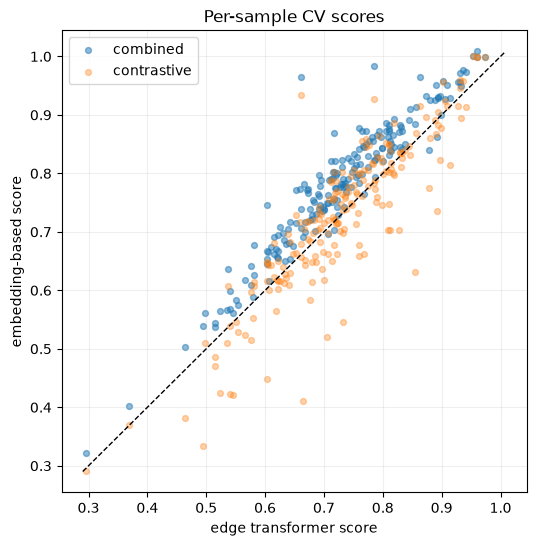

,sample_name,score_transformer,score_contrastive,score_combined,delta_combined_vs_transformer
13,44b6_33b596bf,0.878183,0.774228,0.840814,-0.037369
19,44b6_53f95252,0.891286,0.736243,0.862590,-0.028697
2,44b6_0c582fdc,0.717312,0.678351,0.703789,-0.013523
54,44b6_cf2536e8,0.707225,0.720774,0.696749,-0.010476
63,44b6_deabac95,0.768028,0.662611,0.763889,-0.004140
180,6bba_df673a83,0.899352,0.878300,0.899056,-0.000296
64,44b6_e28840c6,0.724485,0.715641,0.728988,0.004503
106,6bba_48816121,0.786438,0.774048,0.793916,0.007478
42,44b6_9be80b04,0.733626,0.705370,0.741678,0.008052
27,44b6_71a4179f,0.607316,0.599724,0.615611,0.008295


In [37]:
merged = transformer_rows[["sample_name", "score"]].merge(
    contrastive_rows[["sample_name", "score"]],
    on="sample_name",
    suffixes=("_transformer", "_contrastive"),
).merge(
    combined_rows[["sample_name", "score"]].rename(columns={"score": "score_combined"}),
    on="sample_name",
)
merged["delta_combined_vs_transformer"] = merged["score_combined"] - merged["score_transformer"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(merged["score_transformer"], merged["score_combined"], alpha=0.5, s=18, label="combined")
ax.scatter(merged["score_transformer"], merged["score_contrastive"], alpha=0.35, s=18, label="contrastive")
lo = merged[["score_transformer", "score_contrastive", "score_combined"]].min().min()
hi = merged[["score_transformer", "score_contrastive", "score_combined"]].max().max()
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set_xlabel("edge transformer score")
ax.set_ylabel("embedding-based score")
ax.set_title("Per-sample CV scores")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

merged.sort_values("delta_combined_vs_transformer").head(10)

Done !